# Supervised Learning Task: Predicting Spotify Track Popularity
**In the supervised learning part of the project, the goal was to predict the popularity of Spotify tracks using regression models.**

I first prepared the dataset through several preprocessing steps: handling categorical variables with one-hot encoding, selecting numeric features and applying StandardScaler to normalize the feature space. 

I trained a Linear Regression model using the cleaned and scaled dataset and evaluated its performance with the R² score. The results showed that predicting popularity from audio features alone is challenging, since popularity is influenced by many external factors not present in the data. Still, the regression model revealed which acoustic features contribute the most to popularity and helped connect some of the patterns observed in the clustering analysis.

Overall, the supervised regression task provides insight into how measurable audio characteristics relate to the real-world success of songs, highlighting which features have meaningful influence on popularity and which contribute very little.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1686 entries, 0 to 1685
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   energy                    1686 non-null   float64
 1   tempo                     1686 non-null   float64
 2   danceability              1686 non-null   float64
 3   playlist_genre            1686 non-null   object 
 4   loudness                  1686 non-null   float64
 5   liveness                  1686 non-null   float64
 6   valence                   1686 non-null   float64
 7   track_artist              1686 non-null   object 
 8   time_signature            1686 non-null   int64  
 9   speechiness               1686 non-null   float64
 10  track_popularity          1686 non-null   int64  
 11  track_href                1686 non-null   object 
 12  uri                       1686 non-null   object 
 13  track_album_name          1685 non-null   object 
 14  playlist

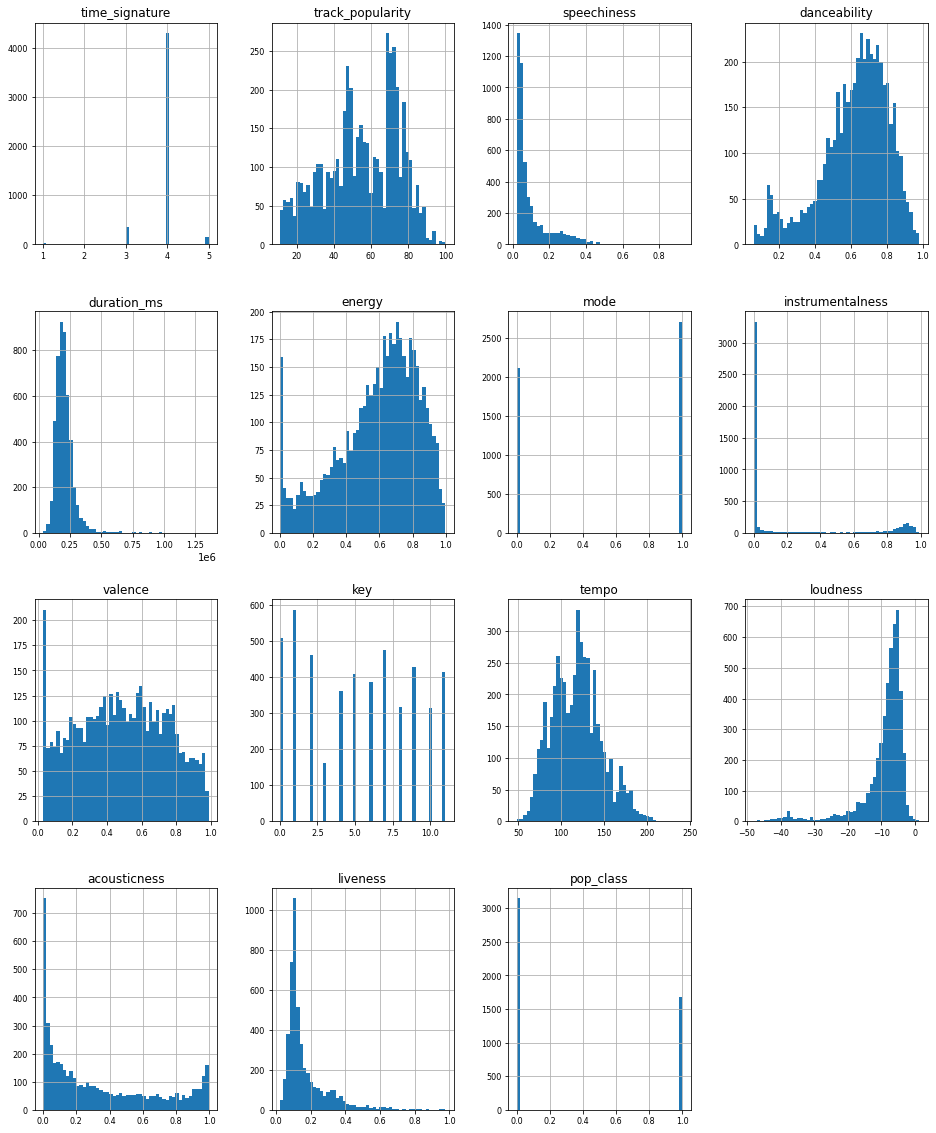

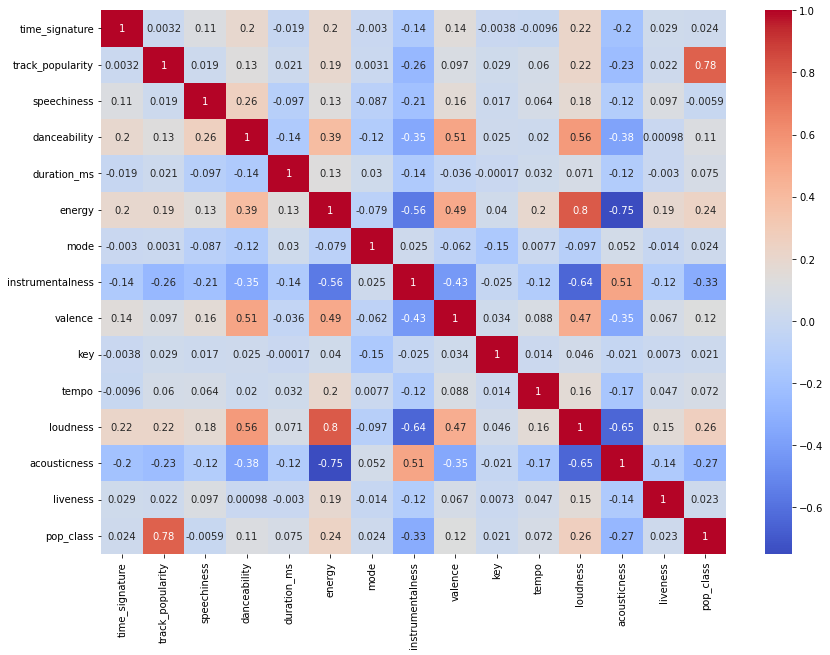

count    4831.000000
mean       54.761126
std        19.828573
min        11.000000
25%        41.000000
50%        56.000000
75%        72.000000
max       100.000000
Name: track_popularity, dtype: float64


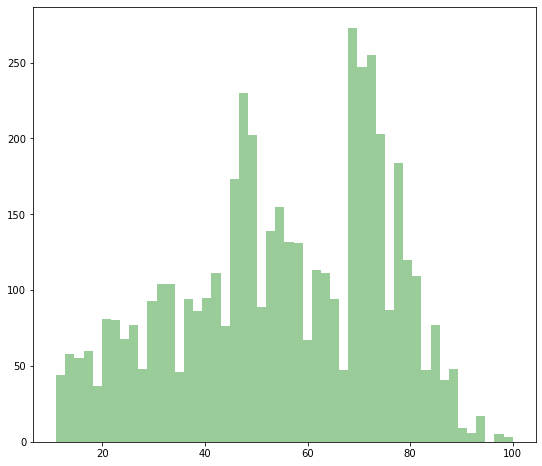

There is 1 strongly correlated values with track_popularity:
pop_class    0.777176
Name: track_popularity, dtype: float64


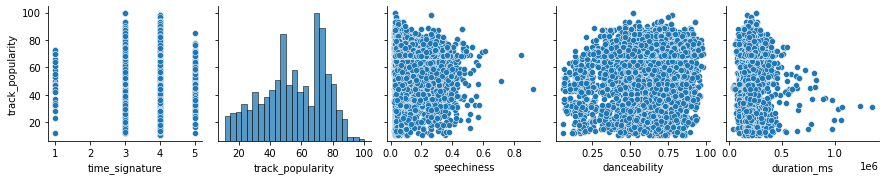

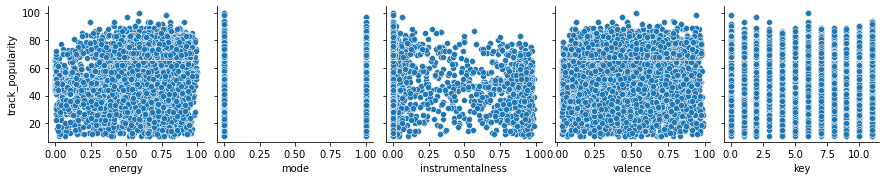

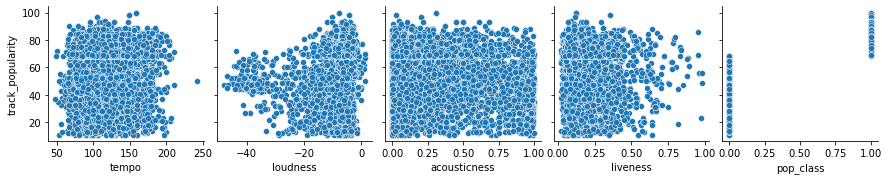

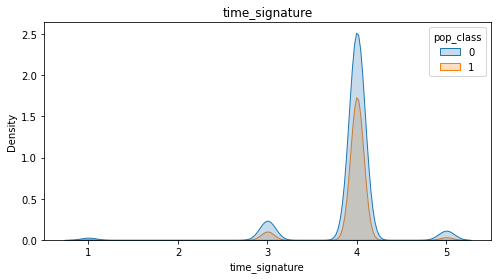

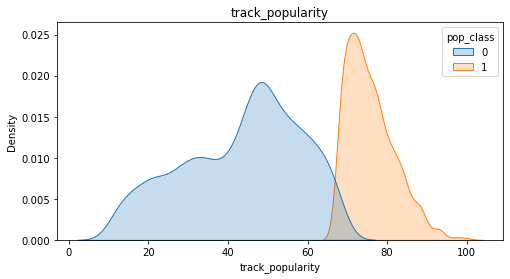

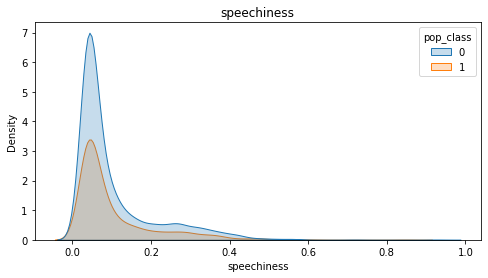

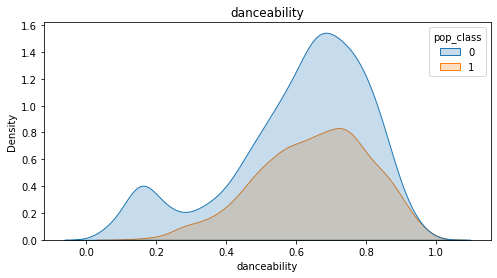

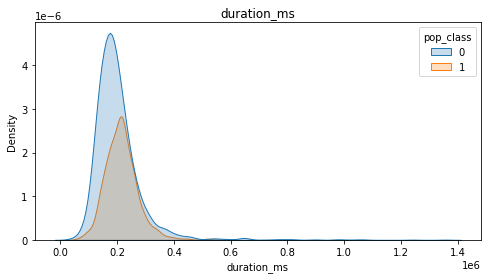

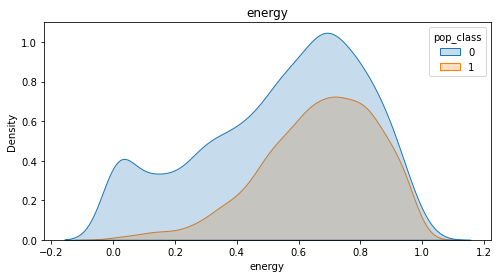

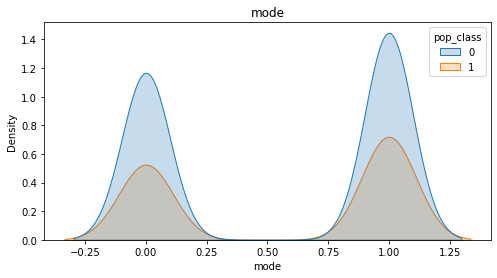

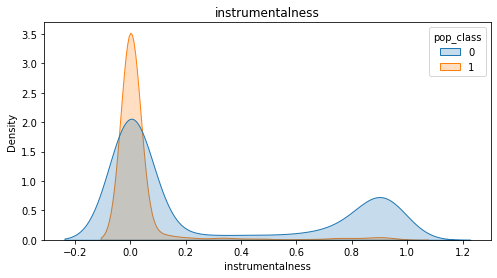

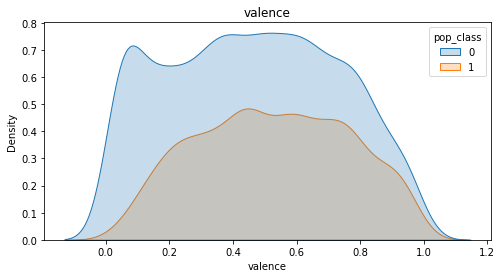

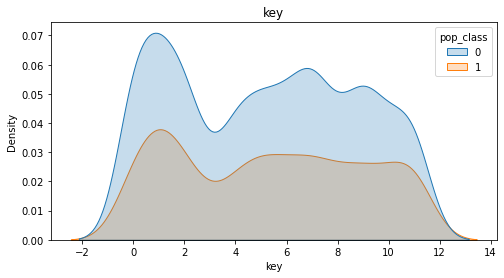

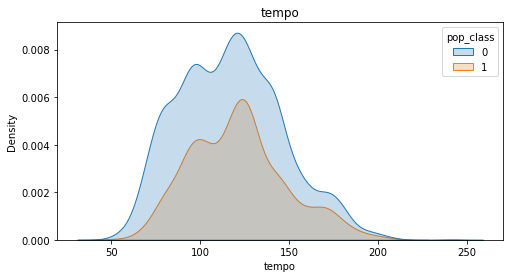

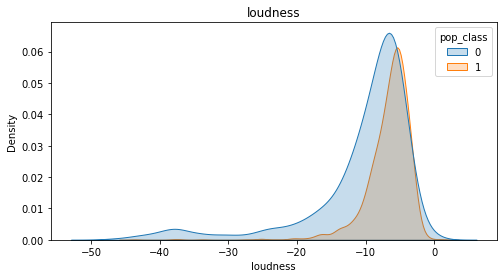

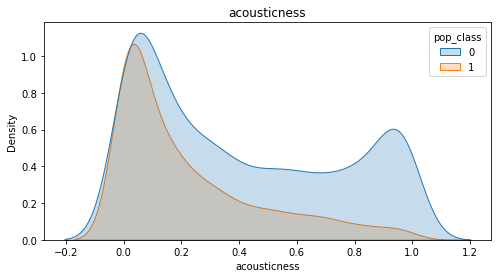

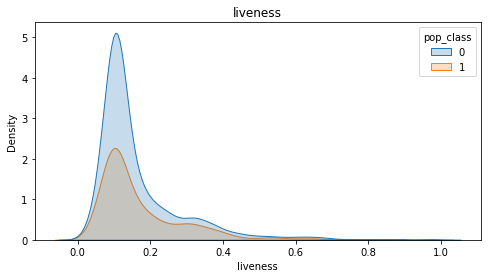

/opt/anaconda3/lib/python3.9/site-packages/seaborn/distributions.py:316: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  warnings.warn(msg, UserWarning)


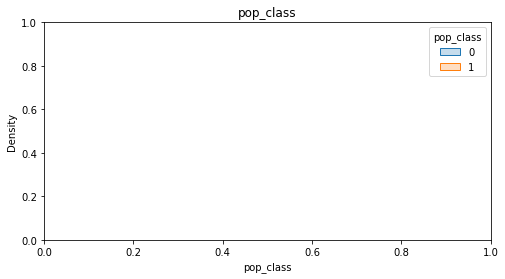

0    0.651004
1    0.348996
Name: pop_class, dtype: float64


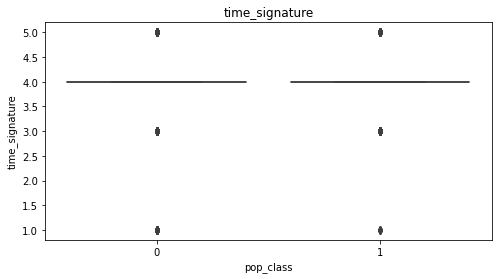

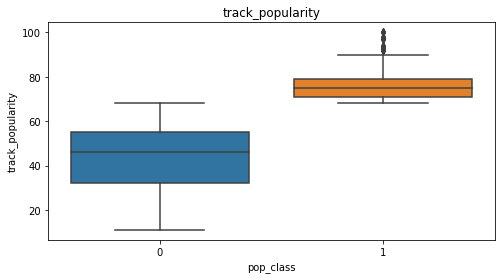

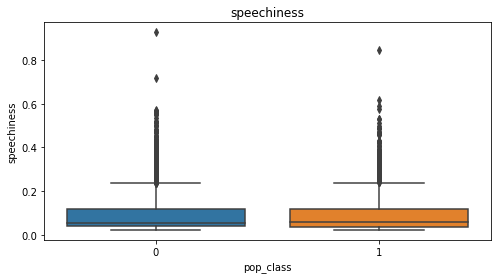

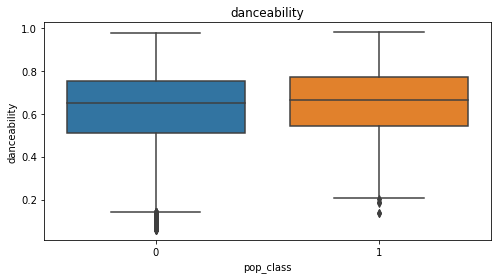

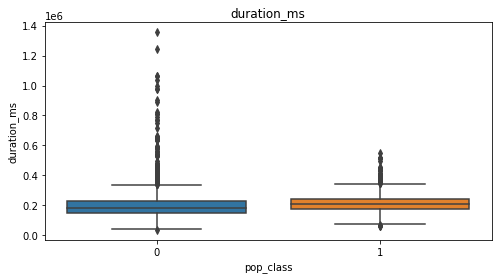

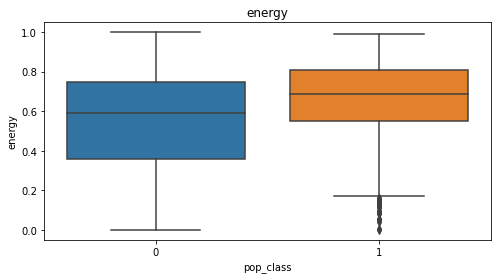

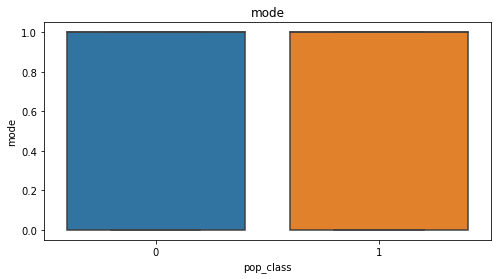

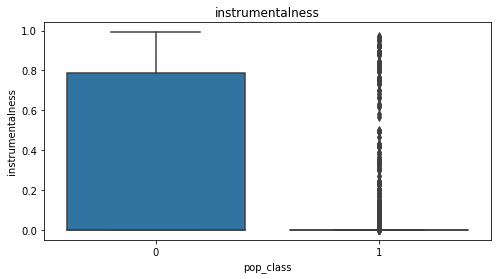

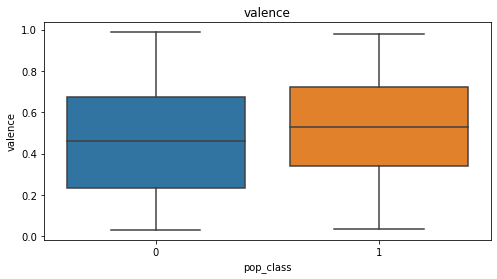

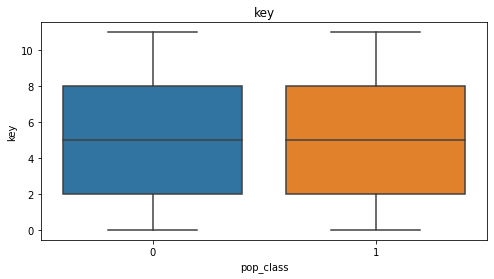

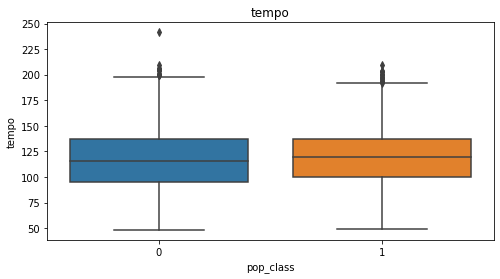

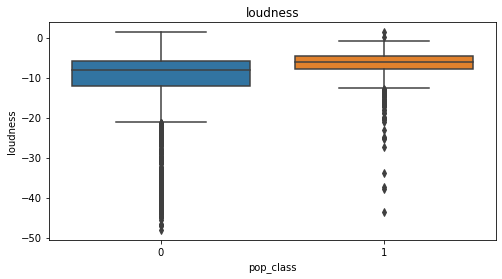

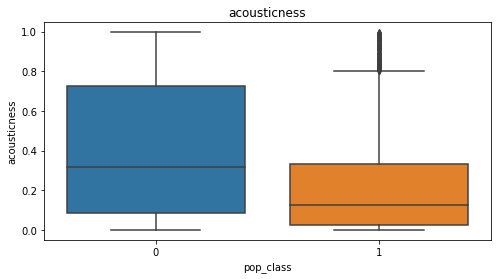

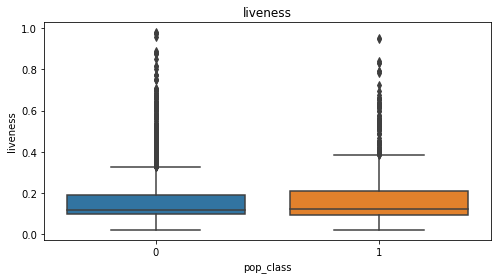

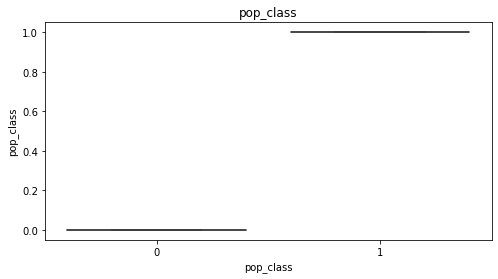

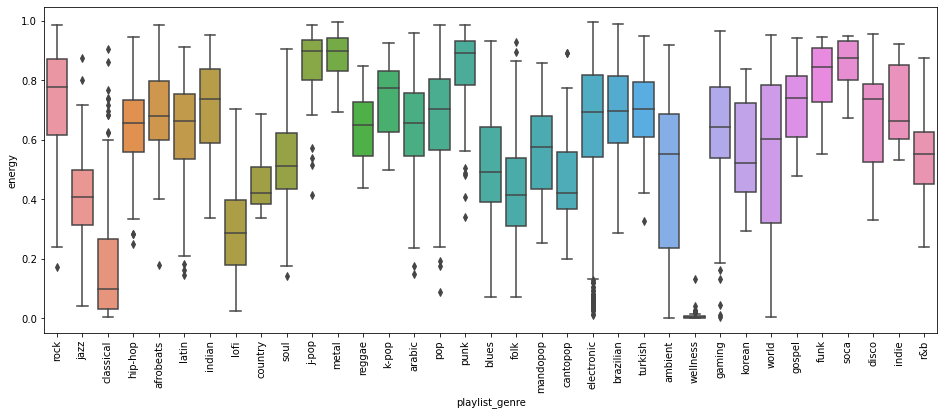

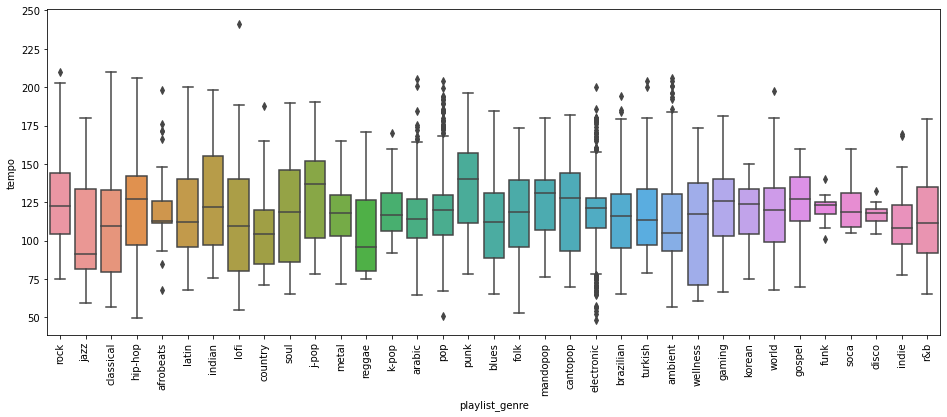

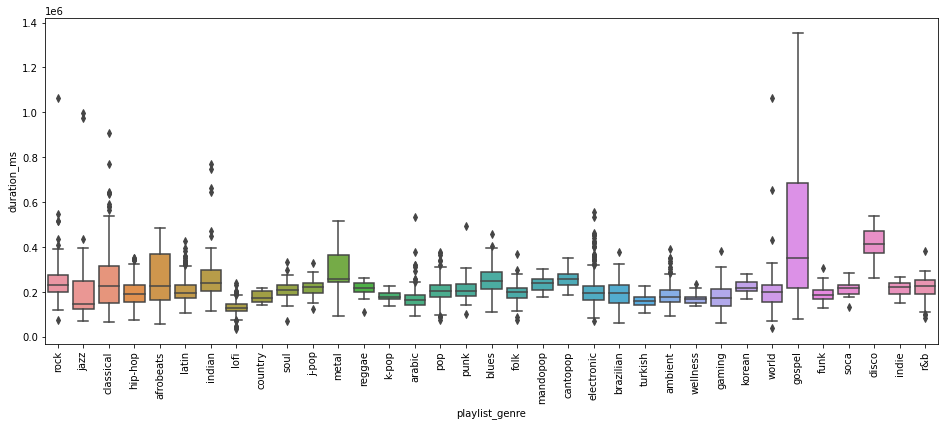

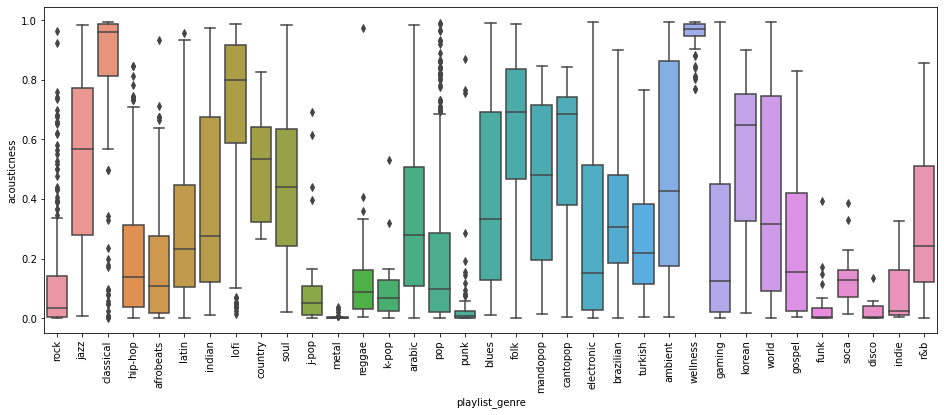

In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures, LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.mixture import GaussianMixture
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn import tree
from scipy.stats import skew
from ipynb.fs.full.ML_Project_EDA import *


# Feature Engineering And Feature Selection

In [2]:
# dropping NA values
for col in df.columns:
    if df[col].dtype != "object":
        df[col] = df[col].fillna(df[col].median())
df = df.dropna(subset=['mode'])
df = df.dropna(subset=['track_album_name'])
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 4830 entries, 0 to 4830
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   time_signature            4830 non-null   float64
 1   track_popularity          4830 non-null   int64  
 2   speechiness               4830 non-null   float64
 3   danceability              4830 non-null   float64
 4   playlist_name             4830 non-null   object 
 5   track_artist              4830 non-null   object 
 6   duration_ms               4830 non-null   float64
 7   energy                    4830 non-null   float64
 8   playlist_genre            4830 non-null   object 
 9   playlist_subgenre         4830 non-null   object 
 10  track_name                4830 non-null   object 
 11  mode                      4830 non-null   float64
 12  type                      4829 non-null   object 
 13  track_album_release_date  4830 non-null   object 
 14  instrume

In [3]:
# --- encoding ---

df = pd.get_dummies(df, columns=['playlist_genre', 'playlist_subgenre', 'type'], drop_first=True)

In [4]:
# Encode playlist names as numeric labels.
le = LabelEncoder()
df['playlist_name'] = le.fit_transform(df['playlist_name'])

In [5]:
# Keep only the top 20 artists, label the rest as 'Other', and encode numerically.
top_artists = df['track_artist'].value_counts().nlargest(20).index
df['track_artist'] = df['track_artist'].apply(lambda x: x if x in top_artists else 'Other')
df['track_artist'] = le.fit_transform(df['track_artist'])

In [6]:
# Target
y = df['track_popularity']

# Features
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop('track_popularity')
numeric_cols = numeric_cols.drop('pop_class')
X = df[numeric_cols].copy()

In [7]:
# Calculate skewness for all numeric features
skewness = X.apply(skew)
skewness.sort_values(ascending=False)

duration_ms         3.984261
liveness            2.356322
speechiness         2.056723
instrumentalness    1.349544
acousticness        0.703522
tempo               0.356351
key                 0.049116
valence            -0.002810
playlist_name      -0.069523
mode               -0.251234
energy             -0.688853
danceability       -0.835773
loudness           -2.682441
track_artist       -2.846399
time_signature     -3.127842
dtype: float64

In [8]:
# Positive skew > 0.7, negative skew < -0.7
pos_skew = skewness[skewness > 0.7].index
neg_skew = skewness[skewness < -0.7].index

In [9]:
# Transform positively skewed features
for col in pos_skew:
    X[col] = np.log1p(X[col])  # log(1+x) to handle zeros

In [10]:
# Transform negatively skewed features
for col in neg_skew:
    X[col] = X[col].max() - X[col]
    X[col] = np.log1p(X[col])

# Correlation-Based Feature Combination

I initially tried to merge the two highly correlated features, **energy** and **loudness**, into a single **energy_loudness_ratio** feature to reduce multicollinearity. However, after applying this transformation, the model’s R² score decreased, indicating worse performance. Based on this, I decided not to combine these features and instead keep them separate, allowing the model to handle the correlation naturally.

In [11]:
# X['energy_loudness_ratio'] = X['energy'] / (X['loudness'] + 1)
# X = X.drop(columns=['energy', 'loudness'])

# Cross-Validation

I also experimented with **cross-validation** to obtain a more robust estimate of model performance. However, applying cross-validation **resulted in lower R² scores** compared to the simple train-test split. Based on this, I decided to continue using the train-test split approach for model evaluation.

In [12]:
# Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled, columns=numeric_cols)

In [13]:
# train test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42
)

# Models

In [14]:
# --- Linear Regression ---
# create the model
lin_reg_model = LinearRegression()

# fit the training data
lin_reg_model.fit(X_train,y_train)

y_pred = lin_reg_model.predict(X_test)
y_pred_train = lin_reg_model.predict(X_train)
# evaluate on training data (RMSE, R2)
mse_train = mean_squared_error(y_train, y_pred_train)
rmse_train = np.sqrt(mse_train)
r2_train = r2_score(y_train, y_pred_train)
# evaluate on test data
mse_test = mean_squared_error(y_test, y_pred)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_test, y_pred)

print(f"MSE_TRAIN: {mse_train:.2f}")
print(f"MSE_TEST: {mse_test:.2f}")
print(f"RMSE_TRAIN: {rmse_train:.2f}")
print(f"RMSE_TEST: {rmse_test:.2f}")
print(f"R²_TRAIN: {r2_train:.3f}")
print(f"R²_TEST: {r2_test:.3f}")

MSE_TRAIN: 344.01
MSE_TEST: 357.55
RMSE_TRAIN: 18.55
RMSE_TEST: 18.91
R²_TRAIN: 0.121
R²_TEST: 0.100



Polynomial Degree: 1
Train MSE: 344.009
Test  MSE: 357.555
Train R²: 0.121
Test  R²: 0.100

Polynomial Degree: 2
Train MSE: 295.844
Test  MSE: 320.492
Train R²: 0.244
Test  R²: 0.193

Polynomial Degree: 3
Train MSE: 222.315
Test  MSE: 623.398
Train R²: 0.432
Test  R²: -0.569

Polynomial Degree: 5
Train MSE: 0.000
Test  MSE: 200636.504
Train R²: 1.000
Test  R²: -503.989


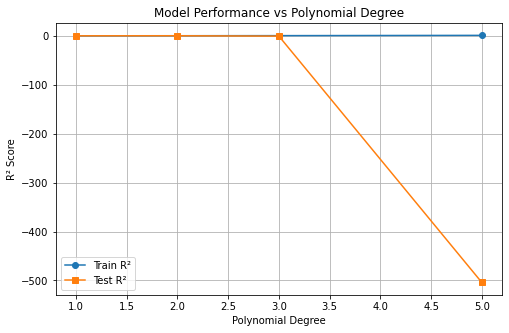

In [15]:
# --- Polynomial Regression ---
# create the model
linear_regression = LinearRegression()

DEGREES = [1, 2, 3, 5]
train_r2_scores = []
test_r2_scores = []
mse_scores = []
rmse_scores = []

for degree in DEGREES:
    polynomial_features = PolynomialFeatures(degree=degree)
    
    # transform input data
    X_p_train = polynomial_features.fit_transform(X_train)
    X_p_test = polynomial_features.transform(X_test)

    # fit model
    linear_regression.fit(X_p_train, y_train)

    # predictions
    y_pred_train = linear_regression.predict(X_p_train)
    y_pred_test = linear_regression.predict(X_p_test)

    # evaluation
    train_mse = mean_squared_error(y_train, y_pred_train)
    test_mse = mean_squared_error(y_test, y_pred_test)
    train_rmse =  np.sqrt(mean_squared_error(y_train, y_pred_train))
    test_rmse =  np.sqrt(mean_squared_error(y_test, y_pred_test))
    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)

    train_r2_scores.append(train_r2)
    test_r2_scores.append(test_r2)
    mse_scores.append(test_mse)
    rmse_scores.append(test_rmse)
    
    print(f"\nPolynomial Degree: {degree}")
    print(f"Train MSE: {train_mse:.3f}")
    print(f"Test  MSE: {test_mse:.3f}")
    print(f"Train R²: {train_r2:.3f}")
    print(f"Test  R²: {test_r2:.3f}")

# --- Plot R² ---
plt.figure(figsize=(8,5))
plt.plot(DEGREES, train_r2_scores, marker='o', label='Train R²')
plt.plot(DEGREES, test_r2_scores, marker='s', label='Test R²')
plt.xlabel('Polynomial Degree')
plt.ylabel('R² Score')
plt.title('Model Performance vs Polynomial Degree')
plt.legend()
plt.grid(True)
plt.show()


In [16]:
# --- Decision Tree ---
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

dt_rmse = np.sqrt(mean_squared_error(y_test, y_pred_dt))
dt_mse = mean_squared_error(y_test, y_pred_dt)
dt_r2 = r2_score(y_test, y_pred_dt)

print("Decision Tree")
print(f"RMSE: {dt_rmse:.3f}")
print(f"MSE: {dt_mse:.3f}")
print(f"R²:   {dt_r2:.3f}\n")


Decision Tree
RMSE: 16.061
MSE: 257.956
R²:   0.351



In [17]:
# --- Random Forest ---
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
y_pred_train_rf = rf.predict(X_train)
y_pred_rf = rf.predict(X_test)

rf_mse_train = mean_squared_error(y_train, y_pred_train_rf)
rf_mse = mean_squared_error(y_test, y_pred_rf)
rf_rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train_rf))
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2_train = r2_score(y_train, y_pred_train_rf)
rf_r2 = r2_score(y_test, y_pred_rf)

print("Random Forest")
print(f"TRAIN RMSE: {rf_rmse_train:.3f}")
print(f"TEST RMSE: {rf_rmse:.3f}")
print(f"TRAIN RMSE: {rf_mse_train:.3f}")
print(f"TEST RMSE: {rf_mse:.3f}")
print(f"TRAIN R²:   {rf_r2_train:.3f}")
print(f"TEST R²:   {rf_r2:.3f}")

Random Forest
TRAIN RMSE: 4.360
TEST RMSE: 11.704
TRAIN RMSE: 19.011
TEST RMSE: 136.975
TRAIN R²:   0.951
TEST R²:   0.655


In [18]:
# -- Lasso feature selection ---

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

lasso = LassoCV(cv=5, random_state=42)
lasso.fit(X_scaled, y)

coefficients = pd.Series(lasso.coef_, index=X.columns)
print("Lasso selected features:\n", coefficients[coefficients != 0].sort_values(ascending=False))


Lasso selected features:
 playlist_name       1.564530
track_artist        1.167184
time_signature      0.833114
key                 0.492845
duration_ms         0.377942
tempo               0.279541
mode                0.266824
liveness           -0.266699
danceability       -0.472268
speechiness        -0.627565
valence            -0.839030
acousticness       -2.743972
instrumentalness   -2.929614
energy             -3.589319
loudness           -4.885618
dtype: float64


In [19]:
# Random Forest with Lasso Selected features
rf_all = RandomForestRegressor(n_estimators=200, random_state=42)
rf_all.fit(X_train, y_train)
r2_all = r2_score(y_test, rf_all.predict(X_test))

selected_features = coefficients[coefficients != 0].index
rf_sel = RandomForestRegressor(n_estimators=200, random_state=42)
rf_sel.fit(X_train[selected_features], y_train)
rf_sel_predict = rf_sel.predict(X_test[selected_features])

r2_sel = r2_score(y_test, rf_sel_predict)
rf_sel_mse = mean_squared_error(y_test, rf_sel_predict)
rf_sel_rmse = np.sqrt(mean_squared_error(y_test, rf_sel_predict))

print(f"R2 (All features): {r2_all:.3f}")
print(f"R2 (Lasso-selected): {r2_sel:.3f}\n")
print(f"MSE (Lasso-selected): {rf_sel_mse:.3f}")
print(f"RMSE (Lasso-selected): {rf_sel_rmse:.3f}")

R2 (All features): 0.655
R2 (Lasso-selected): 0.655

MSE (Lasso-selected): 136.975
RMSE (Lasso-selected): 11.704


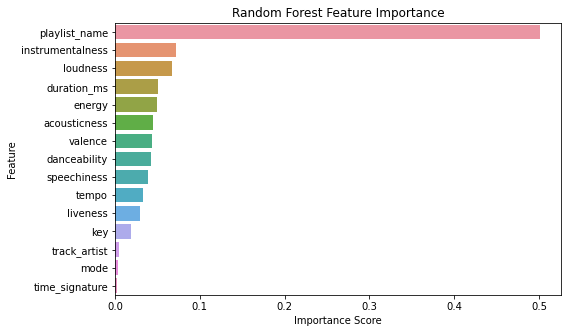

In [20]:
importances = rf.feature_importances_
features = X_train.columns

feat_imp = pd.Series(importances, index=features).sort_values(ascending=False)
plt.figure(figsize=(8,5))
sns.barplot(x=feat_imp, y=feat_imp.index)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()

In [21]:
data = {
    "Linear Regression": [r2_test, mse_test, rmse_test],
    "Polynomial Regresson": [max(test_r2_scores), min(mse_scores), min(rmse_scores)],
    "Decision Tree": [dt_r2, dt_mse, dt_rmse],
    "Random Forest": [rf_r2, rf_mse, rf_rmse],
    "Random Forest With Lasso Selected Features": [r2_sel, rf_sel_mse, rf_sel_rmse]
}

meow = pd.DataFrame(data, index=["R²", "MSE", "RMSE"])
meow

,Linear Regression,Polynomial Regresson,Decision Tree,Random Forest,Random Forest With Lasso Selected Features
R²,0.100059,0.193342,0.350742,0.655242,0.655242
MSE,357.554809,320.492448,257.955832,136.975259,136.975259
RMSE,18.909120,17.902303,16.061003,11.703643,11.703643
